# Questão 2 — MLP para classificação: Wine Quality (UCI)

**Disciplina:** Aprendizado Profundo — UFPB/CI — 2026.2 — Prof. Tiago Maritan

**Objetivo:** prever a qualidade de vinhos (baixa / média / alta) a partir de 11 atributos físico-químicos.

## Conceitos-chave
- **Classificação multiclasse com MLP:** a camada de saída tem **3 neurônios** (um por classe) e a função **softmax** transforma os valores (logits) em probabilidades que somam 1: $p_k = e^{z_k}/\sum_j e^{z_j}$.
- **Perda: entropia cruzada** $L = -\log p_{\text{classe real}}$. Penaliza fortemente quando a rede dá probabilidade baixa à classe certa.
- **Desbalanceamento:** se 77% dos vinhos são "médios", um modelo que **sempre** responde "médio" tem 77% de acurácia e é inútil. Por isso a acurácia sozinha engana; olhamos **precision, recall e F1 por classe** e a **média macro** (média simples entre classes, que dá o mesmo peso à classe rara).

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| Accuracy | acertos / total | quantas previsões estão certas no geral? |
| Precision (classe k) | VP / (VP + FP) | quando o modelo diz "k", quantas vezes acerta? |
| Recall (classe k) | VP / (VP + FN) | dos vinhos que são "k", quantos o modelo encontrou? |
| F1 (classe k) | 2·P·R / (P + R) | média harmônica: só é alta se P e R forem altas |

In [1]:
import os, copy, random, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE, RandomOverSampler

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(); torch.set_num_threads(1)
DATA_DIR = Path(os.environ.get("DATA_DIR", "../data")) / "wine"
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["baixa", "média", "alta"]

## 1. Carregamento
O dataset da UCI (id 186) tem dois arquivos: **1.599 vinhos tintos** e **4.898 brancos** (vinho verde português). Usamos **os dois juntos** (6.497 amostras) e criamos o atributo binário `type` (0 = tinto, 1 = branco), pois a química dos dois tipos é diferente (ex.: brancos têm muito mais SO₂ e açúcar) e a rede precisa saber de qual tipo se trata.

In [2]:
def load_wine(folder: Path) -> pd.DataFrame:
    base = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
    dfs = []
    for cor, t in [("red", 0), ("white", 1)]:
        path = folder / f"winequality-{cor}.csv"
        src = path if path.exists() else base + f"winequality-{cor}.csv"
        d = pd.read_csv(src, sep=";"); d["type"] = t; dfs.append(d)
    return pd.concat(dfs, ignore_index=True)

df_raw = load_wine(DATA_DIR)
print(df_raw.shape); display(df_raw.head())

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


## 2. Análise exploratória
### 2.1 Valores ausentes, tipos e duplicatas

In [3]:
info = pd.DataFrame({"tipo": df_raw.dtypes.astype(str), "ausentes": df_raw.isna().sum(), "distintos": df_raw.nunique()})
display(info)
print(f"Total de valores ausentes: {df_raw.isna().sum().sum()}")
print(f"Linhas duplicadas: {df_raw.duplicated().sum()} ({df_raw.duplicated().mean():.1%})")
display(df_raw.describe().T.style.format("{:.3f}"))

,tipo,ausentes,distintos
fixed acidity,float64,0,106
volatile acidity,float64,0,187
citric acid,float64,0,89
residual sugar,float64,0,316
chlorides,float64,0,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,0,108
sulphates,float64,0,111


Total de valores ausentes: 0
Linhas duplicadas: 1177 (18.1%)


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.000,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.000,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.000,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.000,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.000,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.000,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.000,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.000,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.000,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.000,0.531,0.149,0.220,0.430,0.510,0.600,2.000


- **Nenhum valor ausente** → não é preciso imputação.
- **1.177 linhas duplicadas (18%)**. Decisão: **remover**. Se uma linha idêntica cair no treino e no teste, o modelo é avaliado em algo que já viu — isso infla as métricas (*data leakage*). Após a remoção, cada vinho distinto aparece uma vez.

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("Após remover duplicatas:", df.shape)

Após remover duplicatas: (5320, 13)


### 2.2 Variável alvo: notas → 3 categorias

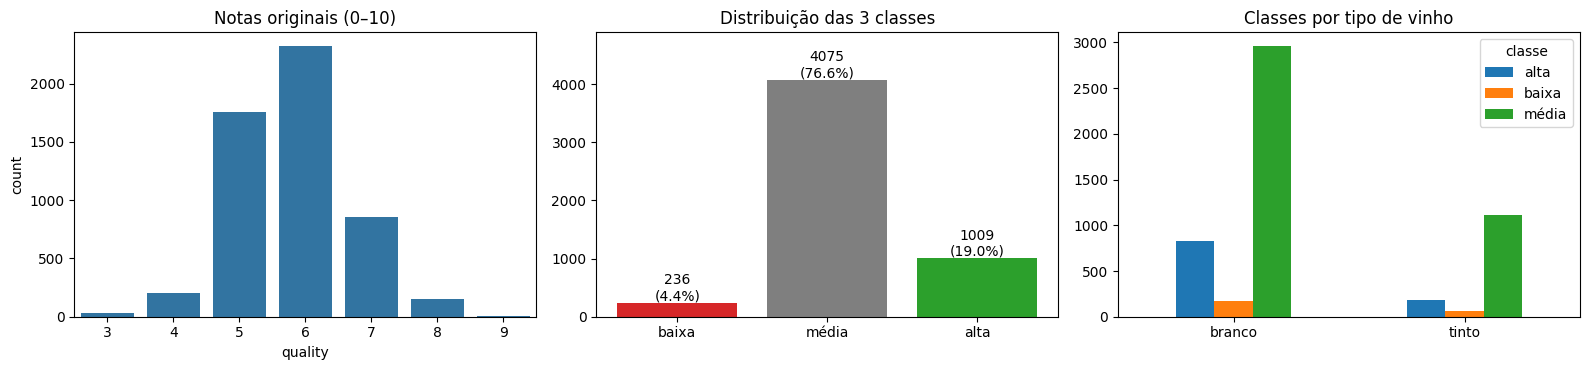

In [5]:
df["classe"] = pd.cut(df["quality"], bins=[-1, 4, 6, 10], labels=[0, 1, 2]).astype(int)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.countplot(x="quality", data=df, ax=ax[0], color="tab:blue"); ax[0].set_title("Notas originais (0–10)")
cnt = df["classe"].value_counts().sort_index()
ax[1].bar(CLASSES, cnt.values, color=["tab:red", "tab:gray", "tab:green"])
for i, v in enumerate(cnt.values): ax[1].text(i, v + 40, f"{v}\n({v / len(df):.1%})", ha="center")
ax[1].set_title("Distribuição das 3 classes"); ax[1].set_ylim(0, cnt.max() * 1.2)
pd.crosstab(df["type"].map({0: "tinto", 1: "branco"}), df["classe"].map(dict(enumerate(CLASSES)))).plot.bar(ax=ax[2], rot=0)
ax[2].set_title("Classes por tipo de vinho"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_classes.png", dpi=120); plt.show()

**Desbalanceamento severo:** "média" ≈ 77%, "alta" ≈ 19%, "baixa" ≈ **4%**. Não existem notas 0, 1, 2 nem 10 — as notas extremas são raras porque são médias de avaliações de especialistas. A classe "baixa" é a mais difícil e a que mais precisará de atenção.

### 2.3 Distribuição dos atributos e assimetria

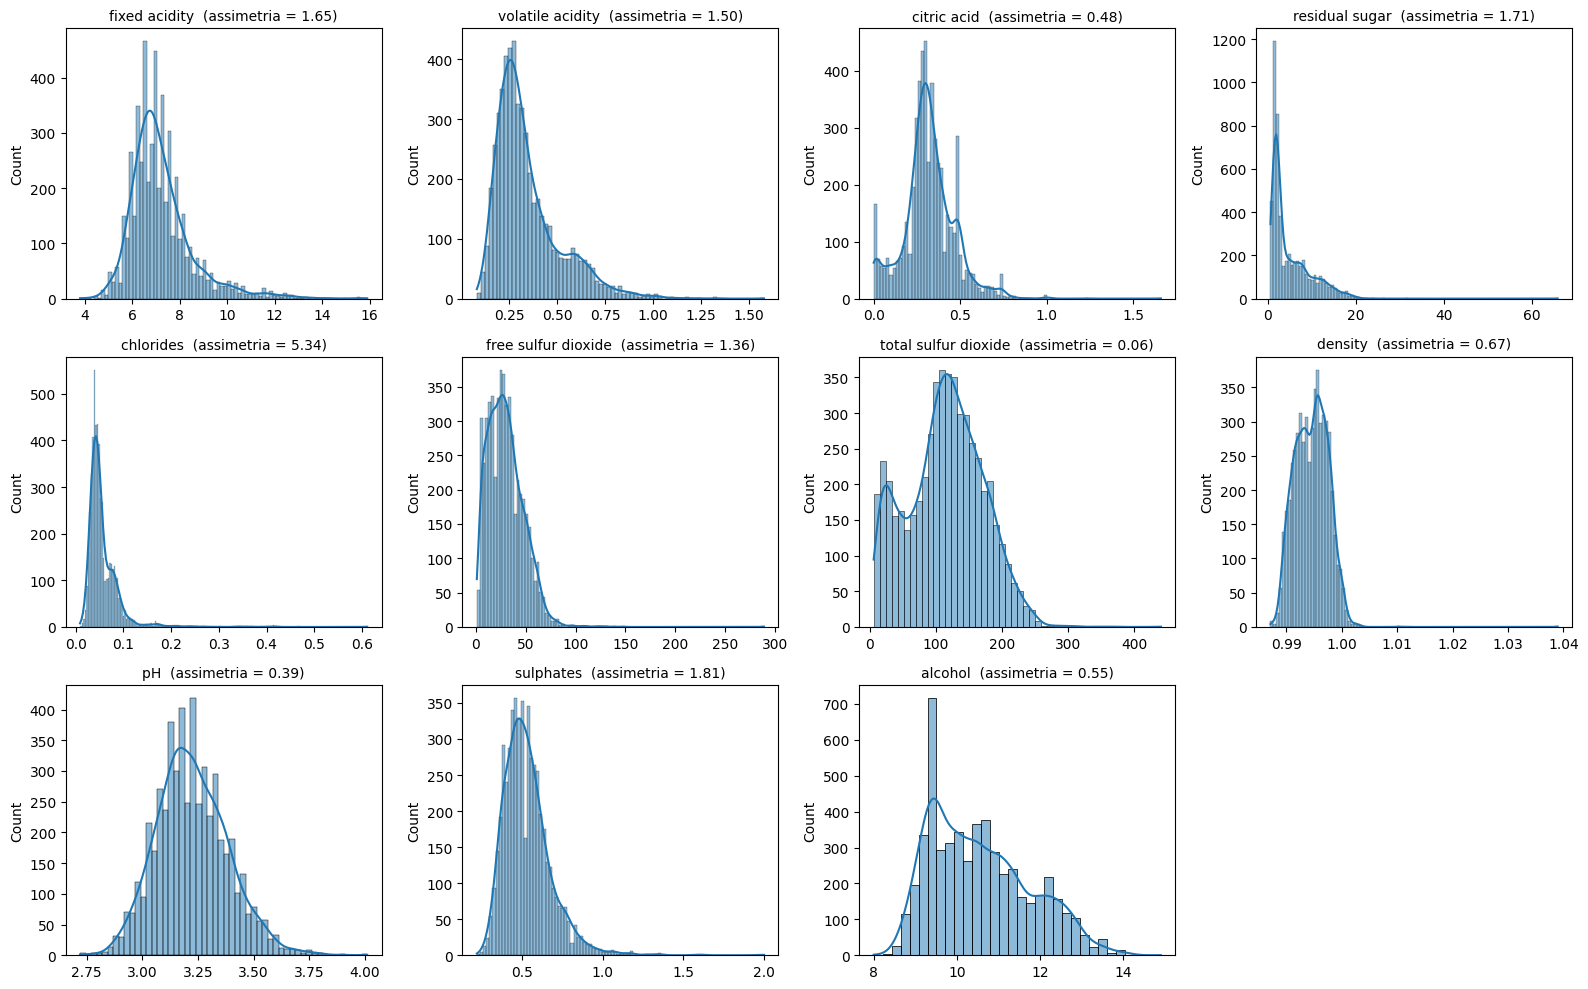

In [6]:
FEATS = [c for c in df.columns if c not in ("quality", "classe")]
num = [c for c in FEATS if c != "type"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num):
    sns.histplot(df[col], kde=True, ax=ax); ax.set_title(f"{col}  (assimetria = {df[col].skew():.2f})", fontsize=10); ax.set_xlabel("")
axes.flat[-1].axis("off"); plt.tight_layout(); plt.savefig(FIG_DIR / "q2_distribuicoes.png", dpi=110); plt.show()

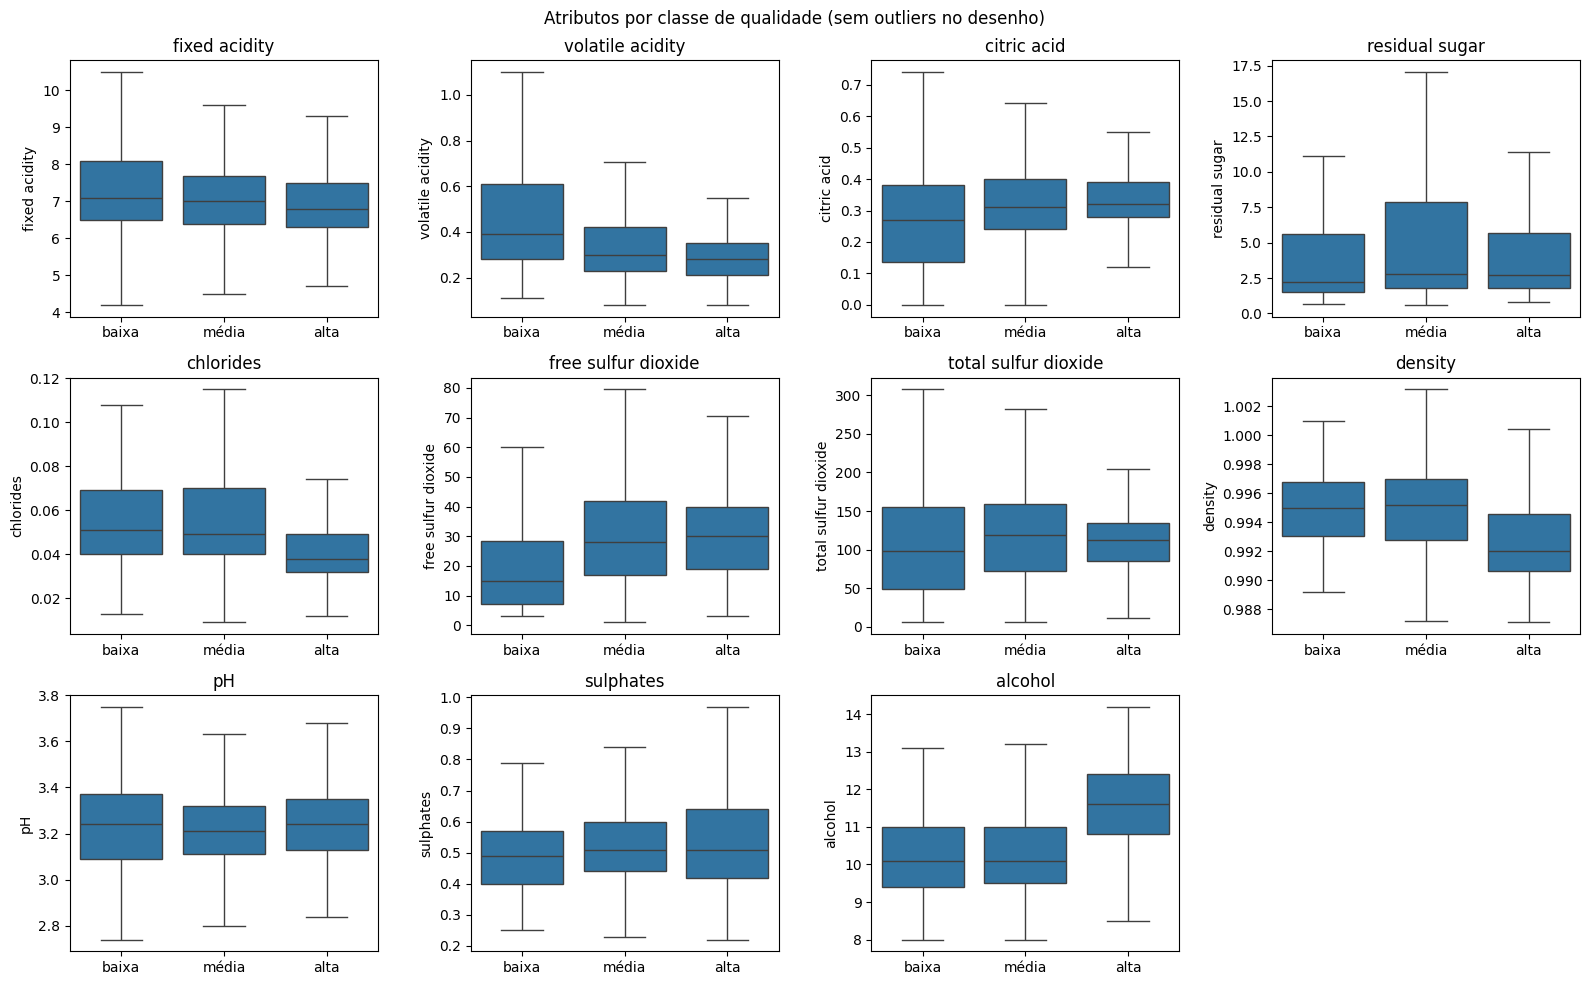

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num):
    sns.boxplot(x=df["classe"].map(dict(enumerate(CLASSES))), y=df[col], ax=ax, order=CLASSES, showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
axes.flat[-1].axis("off"); plt.suptitle("Atributos por classe de qualidade (sem outliers no desenho)")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_boxplot_classes.png", dpi=110); plt.show()

- **Assimetria forte** (cauda à direita) em cloretos (5,4), sulfatos, acidez volátil, acidez fixa, açúcar residual e SO₂ livre → muitos outliers. Aplicaremos **log(1 + x)** nesses atributos para comprimir a cauda antes de padronizar (evita que poucos valores extremos dominem a escala).
- **Atributos mais discriminativos:** **álcool** (vinhos de alta qualidade têm mais álcool — o padrão mais claro), **densidade** (menor nos bons, efeito do álcool), **acidez volátil** (maior nos ruins — sabor de vinagre) e cloretos.

### 2.4 Atributos redundantes: correlação e VIF
Dois atributos são redundantes quando um pode ser previsto pelos outros. Usamos:
- **Correlação de Pearson** (redundância par a par);
- **VIF** (*Variance Inflation Factor*): $\text{VIF}_j = 1/(1-R_j^2)$, em que $R_j^2$ é o R² de prever o atributo $j$ a partir de **todos os outros**. VIF > 10 indica multicolinearidade forte (redundância com uma *combinação* de atributos, que a correlação par a par não enxerga).

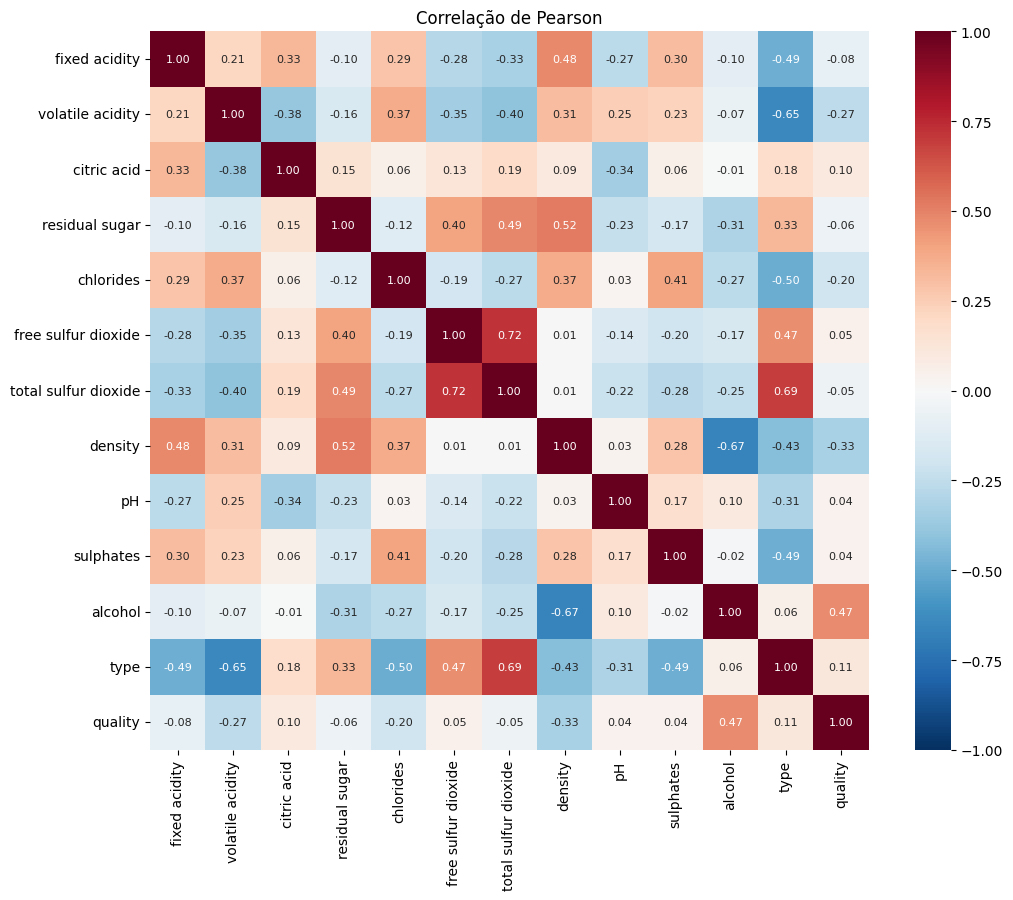

,VIF (todos),VIF (sem density)
alcohol,5.32,1.41
chlorides,1.66,1.64
citric acid,1.67,1.66
density,20.68,—
fixed acidity,5.01,2.19
free sulfur dioxide,2.25,2.22
pH,2.50,1.58
residual sugar,8.42,1.44
sulphates,1.57,1.47
total sulfur dioxide,4.03,3.96


In [8]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FEATS + ["quality"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, annot_kws={"size": 8})
plt.title("Correlação de Pearson"); plt.tight_layout(); plt.savefig(FIG_DIR / "q2_correlacao.png", dpi=110); plt.show()

def vif(frame: pd.DataFrame) -> pd.Series:
    out = {}
    for c in frame.columns:
        X_, y_ = frame.drop(columns=c).values, frame[c].values
        r2 = LinearRegression().fit(X_, y_).score(X_, y_); out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

v_all = vif(df[FEATS]); v_sem = vif(df[FEATS].drop(columns="density"))
display(pd.DataFrame({"VIF (todos)": v_all, "VIF (sem density)": v_sem}).style.format("{:.2f}", na_rep="—").background_gradient(cmap="Reds", vmin=1, vmax=15))

**Diagnóstico de redundância:**
- Par a par, os maiores valores são SO₂ livre × SO₂ total (0,72), densidade × álcool (−0,69) e açúcar residual × densidade (0,55).
- O VIF revela o caso mais forte: **densidade** tem VIF muito acima de 10. Faz sentido físico: a densidade do vinho é determinada quase inteiramente pelo **teor de álcool** (menos denso que a água) e pelo **açúcar** (mais denso). Ela é praticamente uma combinação linear de outros atributos.
- **Decisão:** remover `density`. Ao retirá-la, todos os VIFs caem para valores moderados. SO₂ livre e total são mantidos: correlação de 0,72 não é redundância total, e o SO₂ livre (fração ativa, antimicrobiana) tem significado enológico próprio.
- Na seção 6 verificamos empiricamente que remover `density` **não piora** o modelo (confirma que era redundante).

## 3. Pré-processamento
Ordem importa para não vazar informação do teste:
1. **Split estratificado** 70% treino / 15% validação / 15% teste — "estratificado" mantém a proporção das 3 classes em cada parte (essencial com uma classe de 4%).
2. **Transformação log(1+x)** nos atributos assimétricos (não depende dos dados, pode ser aplicada antes).
3. **Padronização** (`StandardScaler`): média e desvio calculados **só no treino** e aplicados em validação/teste. MLPs são sensíveis à escala: sem isso, o SO₂ total (~100) dominaria cloretos (~0,05) nos produtos $Wx$ e no gradiente.

,treino,validação,teste
baixa,165,35,36
média,2853,611,611
alta,706,152,151


Atributos de entrada: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol', 'type'] | total: 11


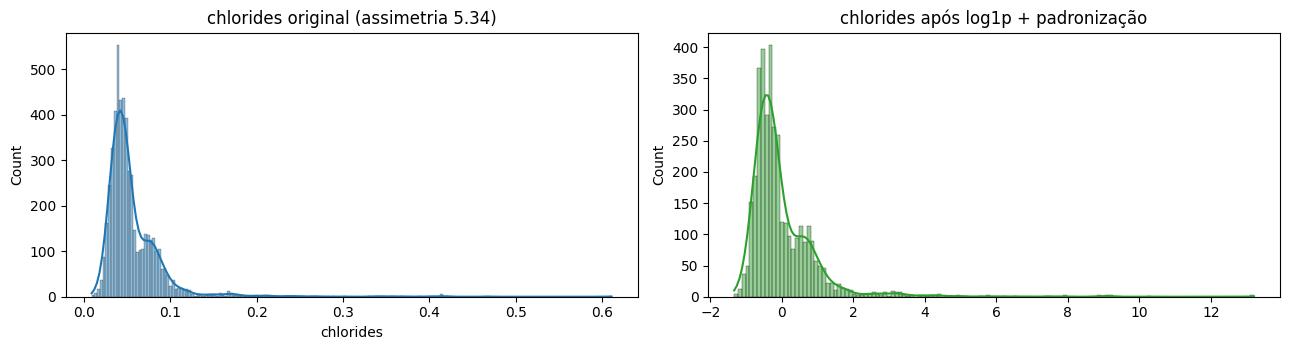

In [9]:
SKEWED = ["fixed acidity", "volatile acidity", "residual sugar", "chlorides", "free sulfur dioxide", "sulphates"]
DROP = ["density"]

def preprocess(frame: pd.DataFrame, drop=DROP) -> pd.DataFrame:
    out = frame[FEATS].drop(columns=drop).copy()
    for c in SKEWED:
        if c in out: out[c] = np.log1p(out[c])
    return out

X_all = preprocess(df); y_all = df["classe"].values
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (scaler.transform(a) for a in (X_train, X_val, X_test))
split_tab = pd.DataFrame({n: pd.Series(y).value_counts().sort_index().values for n, y in
                          [("treino", y_train), ("validação", y_val), ("teste", y_test)]}, index=CLASSES)
display(split_tab)
print("Atributos de entrada:", list(X_all.columns), "| total:", X_all.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sns.histplot(df["chlorides"], ax=ax[0], kde=True); ax[0].set_title(f"chlorides original (assimetria {df['chlorides'].skew():.2f})")
sns.histplot(Xtr[:, list(X_all.columns).index("chlorides")], ax=ax[1], kde=True, color="tab:green")
ax[1].set_title("chlorides após log1p + padronização")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_transformacao.png", dpi=110); plt.show()

## 4. Precisa balancear? Estratégias comparadas
Treinar sem tratamento tende a fazer a rede **ignorar a classe "baixa"**: errar todas as 236 amostras raras custa pouco na perda média. Avaliamos 4 estratégias **com a mesma arquitetura e semente**, escolhendo pela **F1-macro na validação**:

| Estratégia | Como funciona | Prós / contras |
|---|---|---|
| Nenhuma | treino direto | referência; tende a favorecer a maioria |
| **Pesos na perda** | cada classe pesa $\propto 1/\text{frequência}$ na cross-entropy | não altera os dados; erro na classe rara "dói" mais |
| Oversampling aleatório | mantém **todas** as amostras originais e repete (com reposição) amostras das minoritárias até igualar a majoritária | simples; risco de decorar as repetições |
| **SMOTE** | cria amostras sintéticas interpolando vizinhos da mesma classe | mais diversidade que repetir; pode gerar pontos irreais |

**Importante:** qualquer reamostragem é aplicada **somente no treino**. Validação e teste mantêm a distribuição real — é nela que o modelo vai operar.

## 5. Arquitetura da MLP
| Camada | Neurônios | Detalhes |
|---|---|---|
| Entrada | 11 | 10 físico-químicos (sem densidade) + tipo |
| Oculta 1 | 128 | Linear → BatchNorm → ReLU → Dropout(0,3) |
| Oculta 2 | 64 | Linear → BatchNorm → ReLU → Dropout(0,3) |
| Oculta 3 | 32 | Linear → BatchNorm → ReLU → Dropout(0,3) |
| Saída | 3 | logits → softmax |

Treinamento: AdamW (lr = 1e-3, weight decay = 1e-4), mini-lotes de 64, até 300 épocas com **early stopping** (paciência 40) monitorando a **F1-macro de validação**, e `ReduceLROnPlateau` na perda de validação.

In [10]:
class MLPClf(nn.Module):
    def __init__(self, n_in, hidden=(128, 64, 32), n_out=3, p=0.3):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]; d = h
        layers.append(nn.Linear(d, n_out)); self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
TL = lambda a: torch.tensor(np.asarray(a), dtype=torch.long)

def train_clf(Xa, ya, Xv, yv, class_weight=None, epochs=300, lr=1e-3, bs=64, patience=40, seed=SEED, verbose=False):
    set_seed(seed); model = MLPClf(Xa.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=15)
    w = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32)
    Xa_, ya_, Xv_, yv_ = T(Xa), TL(ya), T(Xv), TL(yv)
    hist = {"train_loss": [], "val_loss": [], "val_f1": []}; best, best_state, wait = -1, None, 0
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(ya_))
        for k in range(0, len(ya_), bs):
            idx = perm[k:k + bs]
            if len(idx) < 2: continue
            loss = F.cross_entropy(model(Xa_[idx]), ya_[idx], weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            tr = F.cross_entropy(model(Xa_), ya_, weight=w).item()
            out_v = model(Xv_); vl = F.cross_entropy(out_v, yv_, weight=w).item()
            vf = f1_score(yv, out_v.argmax(1).numpy(), average="macro")
        hist["train_loss"].append(tr); hist["val_loss"].append(vl); hist["val_f1"].append(vf); sched.step(vl)
        if vf > best: best, best_state, wait, best_ep = vf, copy.deepcopy(model.state_dict()), 0, ep
        else: wait += 1
        if wait >= patience: break
    model.load_state_dict(best_state); hist["best_epoch"] = best_ep
    if verbose: print(f"Parou na época {ep}; melhor época {best_ep} (F1-macro val = {best:.4f})")
    return model, hist

def predict(model, X):
    model.eval()
    with torch.no_grad(): p = model(T(X)).softmax(1).numpy()
    return p.argmax(1), p

In [11]:
counts = np.bincount(y_train)
cw = len(y_train) / (3 * counts)          # peso "balanced": n / (n_classes * n_k)
print("Pesos por classe (baixa, média, alta):", cw.round(2))

def make_train(name, X, y):
    """Monta o conjunto de treino de cada estratégia — sempre só com dados de TREINO.
    Retorna (X, y, pesos_da_perda)."""
    if name == "Nenhuma":
        return X, y, None
    if name == "Pesos na perda":
        c = np.bincount(y); return X, y, len(y) / (3 * c)
    if name == "Oversampling aleatório":
        # mantém todas as amostras originais e só ACRESCENTA cópias das classes minoritárias
        Xo, yo = RandomOverSampler(random_state=SEED).fit_resample(X, y); return Xo, yo, None
    if name == "SMOTE":
        Xs, ys = SMOTE(random_state=SEED).fit_resample(X, y); return Xs, ys, None
    raise ValueError(name)

STRATEGIES = ["Nenhuma", "Pesos na perda", "Oversampling aleatório", "SMOTE"]
strategies = {name: make_train(name, Xtr, y_train) for name in STRATEGIES}
results, models, hists = [], {}, {}
for name, (Xa, ya, w) in strategies.items():
    m, h = train_clf(Xa, ya, Xva, y_val, class_weight=w)
    pv, _ = predict(m, Xva)
    p, r, f, _ = precision_recall_fscore_support(y_val, pv, zero_division=0)
    results.append({"Estratégia": name, "n treino": len(ya), "Acurácia val": accuracy_score(y_val, pv),
                    "F1-macro val": f1_score(y_val, pv, average="macro"), "Recall baixa": r[0], "Recall alta": r[2],
                    "Precision baixa": p[0], "melhor época": h["best_epoch"]})
    models[name], hists[name] = m, h
res = pd.DataFrame(results).set_index("Estratégia")
display(res.style.format({c: "{:.3f}" for c in res.columns if c not in ("n treino", "melhor época")}).highlight_max(subset=["F1-macro val"], color="#c6efce"))


Pesos por classe (baixa, média, alta): [7.52 0.44 1.76]


,n treino,Acurácia val,F1-macro val,Recall baixa,Recall alta,Precision baixa,melhor época
Estratégia,,,,,,,
Nenhuma,3724,0.784,0.481,0.029,0.507,0.500,1
Pesos na perda,3724,0.639,0.515,0.543,0.796,0.158,19
Oversampling aleatório,8559,0.667,0.541,0.543,0.803,0.216,36
SMOTE,8559,0.685,0.550,0.514,0.737,0.234,86


**Leitura da comparação:**
- **Sem balanceamento**, a acurácia de validação é a maior (78%), mas o **recall da classe "baixa" é ≈ 3%** — a rede praticamente desiste da classe rara (o melhor F1-macro dessa versão ocorre já na época 1; depois ela converge para "ignorar" os vinhos ruins). Confirma que **é necessário balancear**.
- As três técnicas aumentam fortemente o recall de "baixa" e de "alta", em troca de alguma precisão (mais alarmes falsos nessas classes) e de um pouco de acurácia global. Esse é o *trade-off* clássico precision × recall.
- Escolhemos a estratégia com **maior F1-macro na validação** como modelo final (a escolha é feita na validação, nunca no teste). Nesta execução foi o **SMOTE** (0,550), mas as três técnicas ficam próximas (0,515–0,550): a diferença entre elas é pequena perto da variação entre sementes, e o ponto principal é que **qualquer** balanceamento é muito melhor que nenhum.

In [12]:
best_name = res["F1-macro val"].idxmax()
print("Estratégia escolhida:", best_name)
Xa, ya, w = strategies[best_name]
final_model, final_hist = train_clf(Xa, ya, Xva, y_val, class_weight=w, verbose=True)
print(final_model); print("Parâmetros:", sum(p.numel() for p in final_model.parameters()))

Estratégia escolhida: SMOTE


Parou na época 126; melhor época 86 (F1-macro val = 0.5496)
MLPClf(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=32, out_features=3, bias=True)
  )
)
Parâmetros: 12419


## 6. Curvas de erro de treinamento e validação

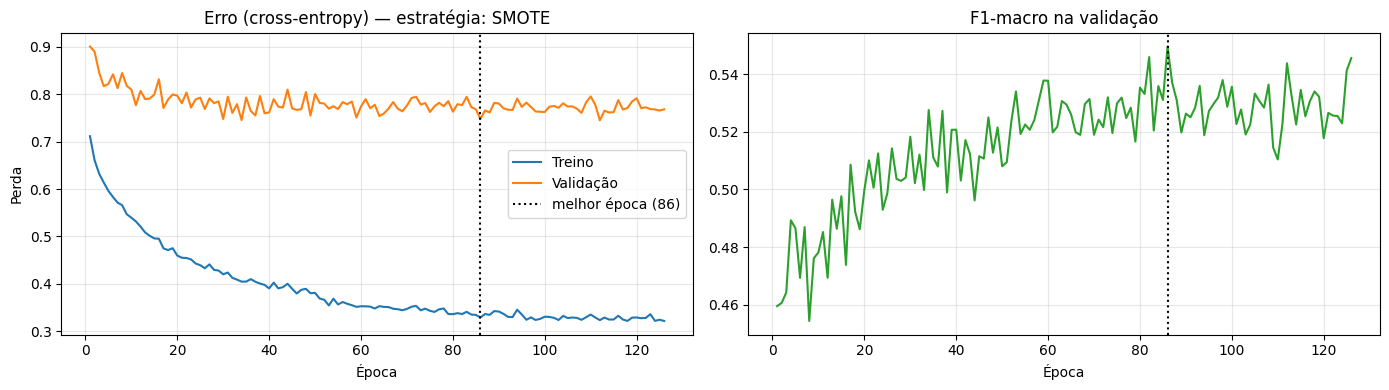

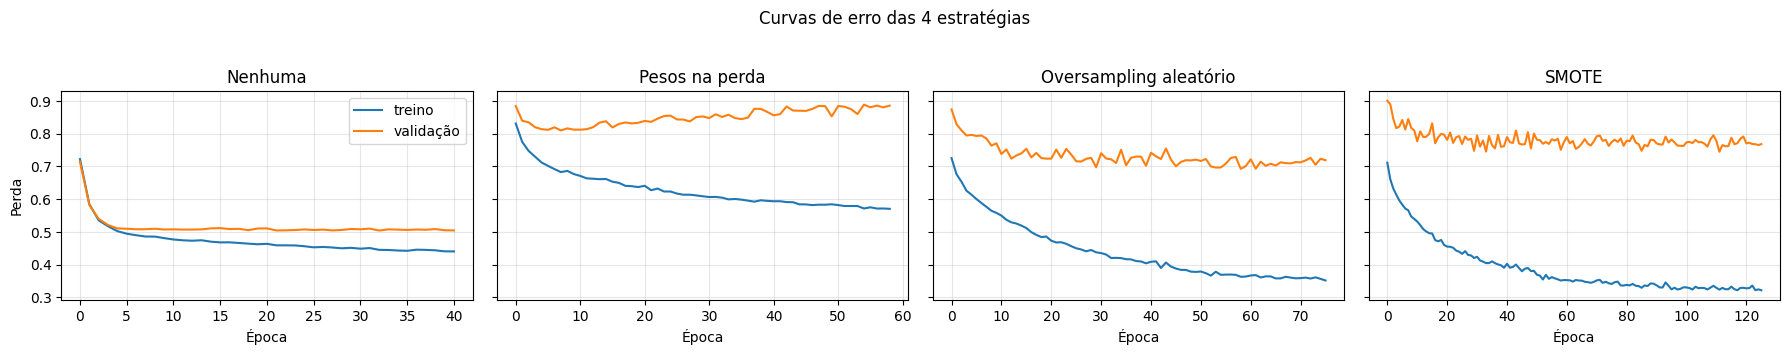

In [13]:
ep = range(1, len(final_hist["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ep, final_hist["train_loss"], label="Treino"); ax[0].plot(ep, final_hist["val_loss"], label="Validação")
ax[0].axvline(final_hist["best_epoch"], ls=":", color="k", label=f"melhor época ({final_hist['best_epoch']})")
ax[0].set(title=f"Erro (cross-entropy) — estratégia: {best_name}", xlabel="Época", ylabel="Perda"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, final_hist["val_f1"], color="tab:green"); ax[1].axvline(final_hist["best_epoch"], ls=":", color="k")
ax[1].set(title="F1-macro na validação", xlabel="Época"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_curvas.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 3.4), sharey=True)
for a, (n, h) in zip(ax, hists.items()):
    a.plot(h["train_loss"], label="treino"); a.plot(h["val_loss"], label="validação"); a.set_title(n); a.grid(alpha=.3); a.set_xlabel("Época")
ax[0].set_ylabel("Perda"); ax[0].legend(); plt.suptitle("Curvas de erro das 4 estratégias", y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_curvas_estrategias.png", dpi=110, bbox_inches="tight"); plt.show()

**Leitura:** a perda de treino continua caindo, enquanto a de validação se estabiliza cedo (≈ 0,77 a partir da época ~20) e não melhora mais → o gap crescente indica que a rede passa a se especializar no treino (overfitting). Por isso o modelo é escolhido pela época de melhor F1-macro na validação, e não pela última. Nas estratégias com reamostragem, a perda de treino fica mais baixa porque as amostras minoritárias repetidas/sintéticas são fáceis de "decorar"; além disso, a validação tem a distribuição **real** (desbalanceada), enquanto o treino reamostrado é equilibrado — as duas perdas não estão na mesma escala, e a curva de validação é a referência.

## 7. Avaliação final no conjunto de TESTE

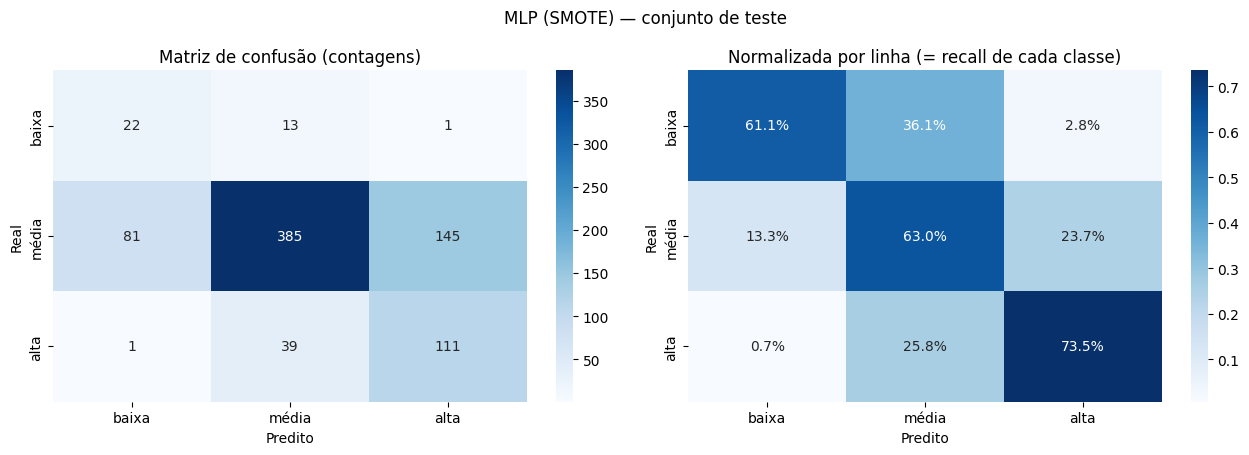

              precision    recall  f1-score   support

       baixa      0.212     0.611     0.314        36
       média      0.881     0.630     0.735       611
        alta      0.432     0.735     0.544       151

    accuracy                          0.649       798
   macro avg      0.508     0.659     0.531       798
weighted avg      0.766     0.649     0.680       798

Accuracy no teste: 0.6491


,precision,recall,f1-score,suporte
baixa,0.212,0.611,0.314,36
média,0.881,0.630,0.735,611
alta,0.432,0.735,0.544,151
média macro,0.508,0.659,0.531,798
média ponderada,0.766,0.649,0.680,798


In [14]:
pred_te, prob_te = predict(final_model, Xte)
cm = confusion_matrix(y_test, pred_te)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set(title="Matriz de confusão (contagens)", xlabel="Predito", ylabel="Real")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".1%", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set(title="Normalizada por linha (= recall de cada classe)", xlabel="Predito", ylabel="Real")
plt.suptitle(f"MLP ({best_name}) — conjunto de teste"); plt.tight_layout()
plt.savefig(FIG_DIR / "q2_matriz_confusao.png", dpi=120); plt.show()

print(classification_report(y_test, pred_te, target_names=CLASSES, digits=3))
p, r, f, s = precision_recall_fscore_support(y_test, pred_te)
final_tab = pd.DataFrame({"precision": p, "recall": r, "f1-score": f, "suporte": s}, index=CLASSES)
final_tab.loc["média macro"] = [p.mean(), r.mean(), f.mean(), s.sum()]
final_tab.loc["média ponderada"] = list(precision_recall_fscore_support(y_test, pred_te, average="weighted")[:3]) + [s.sum()]
print(f"Accuracy no teste: {accuracy_score(y_test, pred_te):.4f}")
display(final_tab.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "suporte": "{:.0f}"}))

### Referências de comparação (no mesmo teste)

In [15]:
def row(nome, yp):
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, yp, average="macro", zero_division=0)
    return {"Modelo": nome, "Accuracy": accuracy_score(y_test, yp), "Precision macro": pr, "Recall macro": rc, "F1 macro": f1}

logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, y_train)
comp = pd.DataFrame([
    row("Sempre 'média' (classe majoritária)", np.ones_like(y_test)),
    row("Regressão logística balanceada", logreg.predict(Xte)),
    row("MLP sem balanceamento", predict(models["Nenhuma"], Xte)[0]),
    row(f"MLP final ({best_name})", pred_te),
]).set_index("Modelo")
display(comp.style.format("{:.3f}"))

,Accuracy,Precision macro,Recall macro,F1 macro
Modelo,,,,
Sempre 'média' (classe majoritária),0.766,0.255,0.333,0.289
Regressão logística balanceada,0.565,0.492,0.683,0.483
MLP sem balanceamento,0.772,0.446,0.441,0.441
MLP final (SMOTE),0.649,0.508,0.659,0.531


### Verificação: remover `density` piorou?
Comparamos com e sem `density` usando **a mesma estratégia de balanceamento do modelo final** e 3 sementes.

In [16]:
X_all_d = preprocess(df, drop=[])
Xa_d, Xt_d = train_test_split(X_all_d, test_size=0.15, stratify=y_all, random_state=SEED)
Xa_d, Xv_d = train_test_split(Xa_d, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)   # mesmos índices do split principal
sc_d = StandardScaler().fit(Xa_d); Xa_d, Xv_d = sc_d.transform(Xa_d), sc_d.transform(Xv_d)
check = {}
for nome, (A, V) in {"sem density (11 atributos)": (Xtr, Xva), "com density (12 atributos)": (Xa_d, Xv_d)}.items():
    A_, y_, w_ = make_train(best_name, A, y_train)          # mesma estratégia do modelo final
    f1s = []
    for s_ in range(3):
        m_, _ = train_clf(A_, y_, V, y_val, class_weight=w_, seed=s_)
        f1s.append(f1_score(y_val, predict(m_, V)[0], average="macro"))
    check[nome] = {"F1-macro val (média 3 sementes)": np.mean(f1s), "desvio": np.std(f1s)}
print("Estratégia de balanceamento usada:", best_name)
display(pd.DataFrame(check).T.style.format("{:.3f}"))


Estratégia de balanceamento usada: SMOTE


,F1-macro val (média 3 sementes),desvio
sem density (11 atributos),0.538,0.009
com density (12 atributos),0.543,0.012


## 8. Discussão
1. **Accuracy engana neste problema.** O classificador trivial "sempre média" tem **76,6%** de acurácia e F1-macro de apenas 0,29. A MLP sem balanceamento chega a 77,2% de acurácia, mas F1-macro 0,44 (quase ignora a classe "baixa"). A MLP final (SMOTE) tem acurácia **menor (64,9%)**, porém **F1-macro 0,53**, recall de "baixa" de **61%** e de "alta" de **74%** — é o modelo mais útil.
2. **Balancear foi necessário — e tem custo.** Com SMOTE, a rede passa a encontrar 22 dos 36 vinhos ruins, mas a **precisão** de "baixa" é só 21%: dos 104 vinhos que ela chama de "baixa", 81 são médios. Como a classe é rara, poucos erros das classes grandes viram muitos falsos positivos em proporção. O recall de "média" cai para 63% (145 médios são chamados de "alta"). Em produção, o limiar de decisão poderia ser ajustado conforme o custo de cada erro (deixar passar um vinho ruim é pior que revisar um médio?).
3. **Onde a rede erra:** quase todos os erros estão entre classes **vizinhas** (baixa ↔ média, média ↔ alta). Confusão baixa ↔ alta só ocorre em **2 das 798** amostras de teste. É coerente: a qualidade é **ordinal** e as notas 4/5 e 6/7 são quimicamente parecidas; a fronteira entre categorias é arbitrária (corte em notas) e a própria avaliação de especialistas tem ruído.
4. **Remover `density`** (testado com a mesma estratégia do modelo final, 3 sementes): F1-macro de validação 0,538 ± 0,009 sem ela × 0,543 ± 0,012 com ela. A diferença (0,005) está dentro da variação entre sementes → a informação de `density` já está nos outros atributos (VIF alto), e o modelo fica mais simples sem ela.
5. **MLP × regressão logística:** no teste, a MLP tem F1-macro maior (0,53 × 0,48) e acurácia bem maior (64,9% × 56,5%); a logística, por outro lado, tem recall macro um pouco maior (0,68 × 0,66), porque marca mais vinhos como "baixa"/"alta". Como é um único split, isso é um **indício** (não uma prova) de que há interações não-lineares entre os atributos (por exemplo, entre teor alcoólico, acidez e o tipo do vinho) que a rede consegue explorar.

**Melhorias possíveis:** tratar o problema como **ordinal** (ex.: regressão da nota + cortes), ajustar o limiar de decisão por classe, ensembles de MLPs, validação cruzada para comparar as estratégias de balanceamento com mais segurança, comparar com Gradient Boosting (costuma ser forte em dados tabulares), e *focal loss* para a classe rara.

> **Nota de correção (revisão):** na versão anterior, o "oversampling aleatório" sorteava **com reposição também a classe majoritária**, o que deixava de fora do treino ≈ 37% dos vinhos "média" distintos. Agora ele usa o `RandomOverSampler`, que mantém todas as amostras originais e só acrescenta cópias das minoritárias. Após a correção, a estratégia com maior F1-macro de validação passou a ser o SMOTE, e os números desta discussão foram atualizados.